# 02 — Features lisibles par famille (rôle A)

Les 2568 colonnes d'EMBER2024 se répartissent en 12 groupes. On compare ensuite les familles sur
12 features faciles à interpréter : ce sont des pistes pour l'analyse d'importance de C, pas
une preuve. Figures enregistrées dans `results/figures/` (préfixe `A_`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from malware_family.dataset import find_dataset, load_dataset
from malware_family.ember_features import PEFILE_WARNINGS, feature_groups
from malware_family.figures import CM, family_colors, new_figure, save_figure, use_style

# Jeu préparé par « python -m malware_family.prepare » : dossier de la variable d'environnement
# EMBER_DATASET, sinon le premier qui existe parmi data/processed/ember2024_Win32_top10 (dans le
# projet), C:\ember2024\processed\Win32_top10 et ~/ember2024/processed/Win32_top10.
DATASET = find_dataset(ROOT)

data = load_dataset(DATASET)
families = data.families
colors = family_colors(families)
use_style()
print(f"{DATASET.name} : {len(data.y_train)} échantillons en train, {len(data.y_test)} en test, "
      f"{len(families)} familles, {len(data.feature_names)} features")

Win32_top10 : 100000 échantillons en train, 30948 en test, 10 familles, 2568 features


## 1. Ce que mesurent les 2568 colonnes

Les colonnes `…_hashNN` regroupent plusieurs noms (« hashing trick ») : pour retrouver les
noms réels, `python -m scripts.hash_lookup` (voir le README).

In [2]:
GROUP_DESCRIPTIONS = {
    "general": "taille et entropie du fichier, fichier PE ou non, 4 premiers octets",
    "histogram": "fréquence de chaque valeur d'octet (0x00 à 0xff)",
    "byteentropy": "histogramme conjoint octet / entropie locale (fenêtres de 2048 octets)",
    "strings": "chaînes imprimables : nombre, longueur, caractères, motifs (URL, IP, registre...)",
    "header": "en-têtes DOS, COFF et optionnel : machine, sous-système, date, tailles, drapeaux",
    "section": "sections : nombre, entropie, tailles, droits, noms hachés ; overlay",
    "imports": "bibliothèques et fonctions importées : nombres et noms hachés",
    "exports": "fonctions exportées : noms hachés",
    "datadirectories": "taille et adresse des 16 data directories (imports, ressources, signature...)",
    "richheader": "Rich header : outils de compilation Microsoft (hachés)",
    "authenticode": "signature numérique : certificats, auto-signature, dates",
    "pefilewarnings": f"anomalies de structure relevées par pefile ({len(PEFILE_WARNINGS)} types + total)",
}
names = data.feature_names
groups = pd.DataFrame([
    {"groupe": group, "colonnes": part.stop - part.start,
     "dont hachées": sum("_hash" in name for name in names[part]),
     "exemple": names[part.start], "contenu": GROUP_DESCRIPTIONS[group]}
    for group, part in feature_groups().items()]).set_index("groupe")
groups.loc["total"] = [groups.colonnes.sum(), groups["dont hachées"].sum(), "", ""]
display(groups)

,colonnes,dont hachées,exemple,contenu
groupe,,,,
general,7,0,general_size,"taille et entropie du fichier, fichier PE ou n..."
histogram,256,0,histogram_byte_0x00,fréquence de chaque valeur d'octet (0x00 à 0xff)
byteentropy,256,0,byteentropy_H00_hi0,histogramme conjoint octet / entropie locale (...
strings,177,0,strings_numstrings,"chaînes imprimables : nombre, longueur, caract..."
header,74,0,header_coff_timestamp,"en-têtes DOS, COFF et optionnel : machine, sou..."
section,224,210,section_count,"sections : nombre, entropie, tailles, droits, ..."
imports,1282,1280,imports_function_count,bibliothèques et fonctions importées : nombres...
exports,129,128,exports_present,fonctions exportées : noms hachés
datadirectories,34,0,datadirectories_EXPORT_size,taille et adresse des 16 data directories (imp...


## 2. Douze features lisibles

| Feature | Ce qu'elle mesure | Pourquoi elle peut distinguer des familles |
|---|---|---|
| `general_size` | taille du fichier (octets) | installeurs et droppers sont souvent plus gros |
| `general_entropy` | entropie du fichier (0 à 8 bits/octet) | proche de 8 : contenu compressé ou chiffré |
| `section_count` | nombre de sections | packers et compilateurs laissent des structures typiques |
| `section_entropy_max` | entropie de la section la plus « aléatoire » | > 7 : section probablement packée |
| `imports_library_count` | bibliothèques importées | un fichier packé importe très peu |
| `imports_function_count` | fonctions importées | idem ; le vrai code est déchiffré à l'exécution |
| `strings_numstrings` | chaînes imprimables | beaucoup de texte en clair, ou presque rien si packé |
| `strings_pattern_url` | chaînes contenant une URL | serveurs de commande, téléchargement |
| `strings_pattern_ipv4_addr` | chaînes contenant une adresse IPv4 | adresses codées en dur |
| `authenticode_num_certs` | certificats de signature | certaines familles signent (certificats volés ou achetés) |
| `richheader_pairs` | entrées du Rich header | chaîne de compilation (Visual Studio, Delphi n'en a pas…) |
| `pefilewarnings_count` | anomalies de structure | fichier malformé ou modifié après compilation |

Les fichiers non PE ont 0 pour toutes les features PE (sections, imports...).

In [3]:
FEATURES = {  # nom : (titre court, échelle de l'axe)
    "general_size": ("Taille (octets)", "symlog"),
    "general_entropy": ("Entropie du fichier", "linear"),
    "section_count": ("Sections", "linear"),
    "section_entropy_max": ("Entropie max. d'une section", "linear"),
    "imports_library_count": ("Bibliothèques importées", "symlog"),
    "imports_function_count": ("Fonctions importées", "symlog"),
    "strings_numstrings": ("Chaînes imprimables", "symlog"),
    "strings_pattern_url": ("Chaînes avec URL", "symlog"),
    "strings_pattern_ipv4_addr": ("Chaînes avec IPv4", "symlog"),
    "authenticode_num_certs": ("Certificats", "linear"),
    "richheader_pairs": ("Entrées Rich header", "linear"),
    "pefilewarnings_count": ("Avertissements pefile", "symlog"),
}
columns = [names.index(feature) for feature in FEATURES]


def readable(X, y):
    """Les 12 features lisibles, avec la famille de chaque ligne."""
    frame = pd.DataFrame(np.asarray(X[:, columns]), columns=list(FEATURES))
    frame["famille"] = pd.Categorical([families[i] for i in y], categories=families)
    return frame


train = readable(data.X_train, data.y_train)
print("Médianes par famille (train) :")
display(train.groupby("famille", observed=False).median().round(2))

Médianes par famille (train) :


,general_size,general_entropy,section_count,section_entropy_max,imports_library_count,imports_function_count,strings_numstrings,strings_pattern_url,strings_pattern_ipv4_addr,authenticode_num_certs,richheader_pairs,pefilewarnings_count
famille,,,,,,,,,,,,
berbew,1.310720e+05,6.99,14.0,7.18,11.0,142.0,981.0,1.0,0.0,0.0,0.0,1.0
cosmu,8.967200e+04,5.87,4.0,6.53,5.0,72.0,1409.5,0.0,0.0,0.0,9.0,1.0
wacatac,7.127040e+05,6.60,5.0,7.26,3.0,15.0,2955.5,0.0,0.0,0.0,3.0,1.0
sfone,3.548255e+05,7.82,5.0,7.88,6.0,9.0,2380.0,0.0,0.0,0.0,0.0,2.0
upatre,4.188300e+04,4.99,4.0,6.34,4.0,27.0,106.0,0.0,0.0,0.0,5.0,1.0
grandoreiro,1.433600e+04,7.41,3.0,7.75,0.0,0.0,121.0,0.0,0.0,0.0,3.0,4.0
glupteba,4.500625e+05,7.61,16.0,7.88,6.0,99.0,1917.0,2.0,0.0,0.0,0.0,1.0
expiro,1.302528e+06,6.60,5.0,7.63,9.0,151.0,3054.0,0.0,1.0,0.0,11.0,1.0
sinowal,3.993600e+05,7.57,5.0,7.80,7.0,152.0,1998.0,0.0,0.0,0.0,11.0,1.0


Figure : results\figures\A_boxplots_features.png


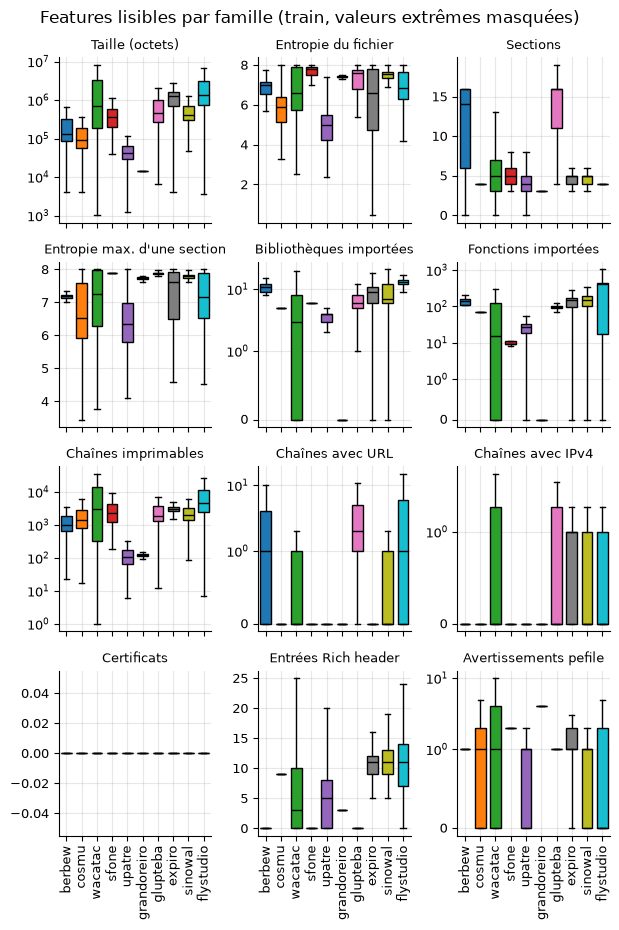

In [4]:
positions = np.arange(1, len(families) + 1)
fig, axes = new_figure(height=24 * CM, nrows=4, ncols=3, sharex=True)
for ax, (feature, (title, scale)) in zip(axes.flat, FEATURES.items()):
    boxes = ax.boxplot([train.loc[train.famille == f, feature] for f in families], positions=positions,
                       widths=0.7, patch_artist=True, showfliers=False, medianprops={"color": "black"})
    for patch, family in zip(boxes["boxes"], families):
        patch.set_facecolor(colors[family])
    if scale == "symlog":
        ax.set_yscale("symlog", linthresh=1)
    ax.set_title(title, fontsize=9)
ax.set_xticks(positions, families)  # axes partagés : étiquettes sur la dernière ligne seulement
for ax in axes[-1]:
    ax.tick_params(axis="x", labelrotation=90)
fig.suptitle("Features lisibles par famille (train, valeurs extrêmes masquées)")
fig.tight_layout()
print("Figure :", save_figure(fig, "A_boxplots_features").relative_to(ROOT))

Beaucoup de ces features valent 0 pour la plupart des fichiers (pas de signature, pas d'URL...) :
la boîte se réduit alors à un trait. La part des échantillons où la feature est non nulle est
plus parlante.

Figure : results\figures\A_part_non_nulle_features.png


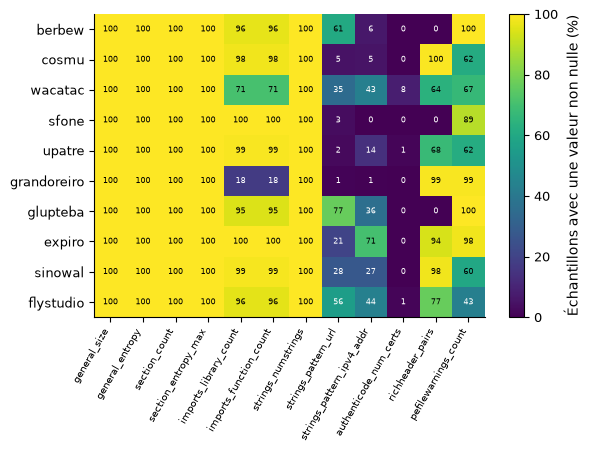

In [5]:
share = 100 * (train[list(FEATURES)] > 0).groupby(train.famille, observed=False).mean()
fig, ax = new_figure(height=10 * CM)
image = ax.imshow(share.to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=100)
for (i, j), value in np.ndenumerate(share.to_numpy()):
    ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=6,
            color="white" if value < 60 else "black")
ax.set_xticks(range(len(FEATURES)), list(FEATURES), rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(families)), families)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Échantillons avec une valeur non nulle (%)")
print("Figure :", save_figure(fig, "A_part_non_nulle_features").relative_to(ROOT))

**À compléter après exécution sur les vraies données :**

- Familles probablement packées (entropie maximale élevée, peu d'imports) : …
- Familles qui signent leurs fichiers : …
- Familles avec des URL ou des adresses IP en clair : …
- Features qui semblent ne distinguer aucune famille : …
- Pistes pour C (features à vérifier dans l'analyse d'importance) : …